# Vélib' Métropole : une station sera-t-elle vide dans 30 minutes ?

**DATA-IA-EXE710 · Télécom Paris · Kit Data Science**

Dans ce notebook, on analyse les instantanés Vélib' que notre collecteur enregistre toutes les 5 minutes environ (dossier `data/raw/`). Toutes les données sont réelles : il suffit de relancer le notebook à la fin de la collecte pour mettre à jour les résultats.

**Plan**
1. Chargement des données
2. Couverture de la collecte
3. Qualité des données
4. Le champ `last_reported`
5. Exploration
6. Construction de la cible « vide dans 30 min »
7. Modèles et évaluation
8. Conclusion et limites

**Définitions**
- une station est **en service** si `is_renting == 1` ;
- une station est **vide** si elle est en service et que `num_bikes_available == 0` ;
- la **cible** vaut 1 si la station est en service maintenant et dans 30 minutes, et qu'elle n'a plus aucun vélo dans 30 minutes.

## 1. Chargement des données

In [ ]:
# Récupérer le dépôt GitHub (dans Colab) ou utiliser le dossier local.
import os

if os.path.exists("../data/raw"):           # notebook lancé depuis le dossier notebooks/
    DOSSIER = ".."
elif os.path.exists("data/raw"):            # notebook lancé depuis la racine du dépôt
    DOSSIER = "."
else:                                       # Colab : on clone le dépôt
    if not os.path.exists("velib-kit-data-science"):
        os.system("git clone --depth 1 https://github.com/G-Akram01/velib-kit-data-science.git")
    DOSSIER = "velib-kit-data-science"

print("Dossier du projet :", DOSSIER)

Dossier du projet : velib-kit-data-science


In [ ]:
import glob
import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Les heures de collecte sont en UTC ; on les convertit en heure de Paris pour les graphiques.
plt.rcParams["date.autoformatter.hour"] = "%d/%m %Hh"
plt.rcParams["date.autoformatter.day"] = "%d/%m"
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

BLEU = "#2a78d6"
ORANGE = "#eb6834"
GRIS = "#8a8984"

In [ ]:
def lire_json_gz(chemin):
    with gzip.open(chemin, "rt", encoding="utf-8") as f:
        return json.load(f)


def nb_velos_type(liste_types, type_velo):
    """Extrait le nombre de vélos 'mechanical' ou 'ebike' de num_bikes_available_types."""
    if not isinstance(liste_types, list):
        return np.nan
    for element in liste_types:
        if type_velo in element:
            return element[type_velo]
    return np.nan


fichiers = sorted(glob.glob(f"{DOSSIER}/data/raw/*/*.json.gz"))
print("Nombre de fichiers :", len(fichiers))

morceaux = []
for chemin in fichiers:
    contenu = lire_json_gz(chemin)
    stations = pd.DataFrame(contenu["stations"])
    stations["collecte"] = contenu["collected_at_utc"]
    morceaux.append(stations)

df = pd.concat(morceaux, ignore_index=True)
print("Dimensions :", df.shape)
df.head()

Nombre de fichiers : 2078
Dimensions : (3157511, 13)


,station_id,num_bikes_available,numBikesAvailable,num_bikes_available_types,num_docks_available,numDocksAvailable,is_installed,is_returning,is_renting,last_reported,stationCode,station_opening_hours,collecte
0,213688169,2,2,"[{'mechanical': 1}, {'ebike': 1}]",33,33,1,1,1,1792861665,16107,None,2026-10-24T17:55:14+00:00
1,19179944124,26,26,"[{'mechanical': 24}, {'ebike': 2}]",1,1,1,1,1,1792861861,40001,None,2026-10-24T17:55:14+00:00
2,18795078746,2,2,"[{'mechanical': 1}, {'ebike': 1}]",26,26,1,1,1,1792861540,32304,None,2026-10-24T17:55:14+00:00
3,36255,3,3,"[{'mechanical': 0}, {'ebike': 3}]",18,18,1,1,1,1792862027,9020,None,2026-10-24T17:55:14+00:00
4,251039991,5,5,"[{'mechanical': 1}, {'ebike': 4}]",20,20,1,1,1,1792861766,14111,None,2026-10-24T17:55:14+00:00


In [ ]:
# On garde les colonnes utiles avec des noms plus simples.
df["collecte"] = pd.to_datetime(df["collecte"], utc=True)
df["station_id"] = df["station_id"].astype(str)
df["velos_meca"] = df["num_bikes_available_types"].apply(lambda x: nb_velos_type(x, "mechanical"))
df["velos_elec"] = df["num_bikes_available_types"].apply(lambda x: nb_velos_type(x, "ebike"))

df = df.rename(columns={
    "num_bikes_available": "velos",
    "num_docks_available": "bornes_libres",
    "is_renting": "en_service",
})
df = df[["station_id", "collecte", "velos", "velos_meca", "velos_elec", "bornes_libres",
         "en_service", "is_installed", "is_returning", "last_reported"]]

# Le cron GitHub n'est pas à l'heure pile : on arrondit chaque relevé aux 5 minutes les plus proches.
df["temps"] = df["collecte"].dt.round("5min").dt.tz_convert("Europe/Paris")
# Si deux relevés tombent sur le même créneau (lancement manuel), on garde le dernier.
df = df.sort_values("collecte").drop_duplicates(["station_id", "temps"], keep="last")
df.head()

,station_id,collecte,velos,velos_meca,velos_elec,bornes_libres,en_service,is_installed,is_returning,last_reported,temps
0,213688169,2026-10-24 17:55:14+00:00,2,1.0,1.0,33,1,1,1,1792861665,2026-10-24 19:55:00+02:00
1018,128834707,2026-10-24 17:55:14+00:00,11,11.0,0.0,10,1,1,1,1792862001,2026-10-24 19:55:00+02:00
1017,49423507,2026-10-24 17:55:14+00:00,69,48.0,21.0,4,1,1,1,1792862043,2026-10-24 19:55:00+02:00
1016,11908496227,2026-10-24 17:55:14+00:00,1,1.0,0.0,23,1,1,1,1792861901,2026-10-24 19:55:00+02:00
1015,54000537,2026-10-24 17:55:14+00:00,12,9.0,3.0,3,1,1,1,1792861783,2026-10-24 19:55:00+02:00


In [ ]:
# On limite l'analyse à la période où la collecte était régulière
date_fin = pd.Timestamp("2026-10-31 23:59:59", tz="Europe/Paris")

df = df[df["temps"] <= date_fin].copy()

print("Dernière date conservée :", df["temps"].max())
print("Nombre de lignes conservées :", len(df))

Dernière date conservée : 2026-10-31 22:55:00+01:00
Nombre de lignes conservées : 3076969


In [ ]:
# Référentiel des stations : nom, position, capacité (on prend le fichier le plus récent).
fichiers_ref = sorted(glob.glob(f"{DOSSIER}/data/reference/station_information_*.json.gz"))
ref = pd.DataFrame(lire_json_gz(fichiers_ref[-1])["stations"])
ref["station_id"] = ref["station_id"].astype(str)
ref = ref[["station_id", "name", "lat", "lon", "capacity"]]
print("Stations dans le référentiel :", len(ref))
ref.head()

Stations dans le référentiel : 1520


,station_id,name,lat,lon,capacity
0,213688169,Benjamin Godard - Victor Hugo,48.865983,2.275725,35
1,19179944124,Hôpital Mondor,48.798922,2.453745,28
2,18795078746,Charcot - Benfleet,48.878370,2.440524,28
3,36255,Toudouze - Clauzel,48.879296,2.337360,21
4,251039991,Cassini - Denfert-Rochereau,48.837526,2.336035,25


## 2. Couverture de la collecte

Le flux Vélib' ne donne que l'état actuel des stations : si un relevé est manqué, il est perdu. Il faut donc vérifier combien de relevés on a vraiment et où sont les trous.

In [ ]:
releves = pd.Series(sorted(df["temps"].unique()))
debut, fin = releves.min(), releves.max()
duree_heures = (fin - debut).total_seconds() / 3600
attendus = int(duree_heures * 60 / 5) + 1

print("Début :", debut.tz_convert("Europe/Paris"))
print("Fin   :", fin.tz_convert("Europe/Paris"))
print(f"Durée : {duree_heures:.1f} h")
print(f"Relevés attendus : {attendus} | relevés obtenus : {len(releves)} | couverture : {len(releves) / attendus:.1%}")

# Trous : écart de plus de 5 minutes entre deux relevés consécutifs.
ecarts = releves.diff().dt.total_seconds() / 60
trous = pd.DataFrame({"avant le trou": releves.shift(1).dt.tz_convert("Europe/Paris"),
                      "après le trou": releves.dt.tz_convert("Europe/Paris"),
                      "durée (min)": ecarts})
trous = trous[trous["durée (min)"] > 5].sort_values("durée (min)", ascending=False)
print("Nombre de trous :", len(trous), "| dont plus de 15 min :", (trous["durée (min)"] > 15).sum())
trous.head(10)

Début : 2026-10-24 19:55:00+02:00
Fin   : 2026-10-31 22:55:00+01:00
Durée : 172.0 h
Relevés attendus : 2065 | relevés obtenus : 2025 | couverture : 98.1%
Nombre de trous : 8 | dont plus de 15 min : 3


,avant le trou,après le trou,durée (min)
2,2026-10-24 20:10:00+02:00,2026-10-24 22:05:00+02:00,115.0
3,2026-10-24 22:05:00+02:00,2026-10-24 22:40:00+02:00,35.0
2024,2026-10-31 22:20:00+01:00,2026-10-31 22:55:00+01:00,35.0
1,2026-10-24 19:55:00+02:00,2026-10-24 20:10:00+02:00,15.0
522,2026-10-26 16:50:00+01:00,2026-10-26 17:00:00+01:00,10.0
1235,2026-10-29 04:20:00+01:00,2026-10-29 04:30:00+01:00,10.0
1654,2026-10-30 15:20:00+01:00,2026-10-30 15:30:00+01:00,10.0
1694,2026-10-30 18:45:00+01:00,2026-10-30 18:55:00+01:00,10.0


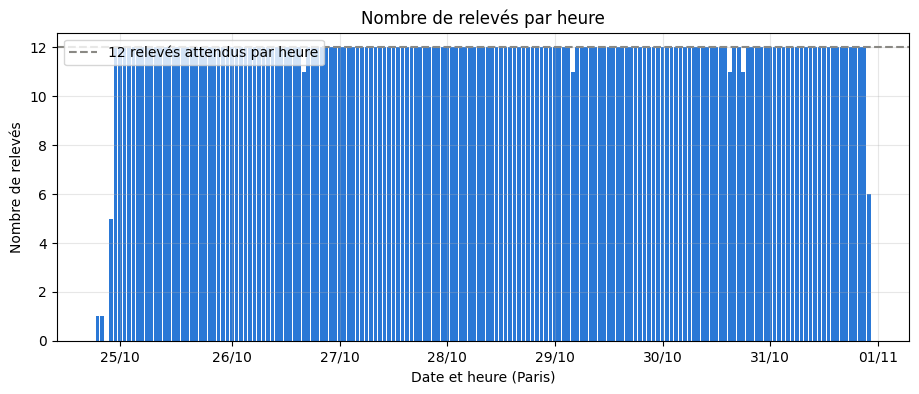

In [ ]:
par_heure = releves.dt.tz_convert("UTC").dt.floor("h").dt.tz_convert("Europe/Paris").value_counts().sort_index()

plt.bar(par_heure.index, par_heure.values, width=0.035, color=BLEU)
plt.axhline(12, color=GRIS, linestyle="--", label="12 relevés attendus par heure")
plt.title("Nombre de relevés par heure")
plt.xlabel("Date et heure (Paris)")
plt.ylabel("Nombre de relevés")
plt.legend()
plt.show()

**Commentaire.** Le cron de GitHub Actions est prévu toutes les 5 minutes mais il n'est pas garanti : les relevés arrivent avec 1 à 3 minutes de retard (corrigé par l'arrondi) et il y a quelques trous, surtout au démarrage du workflow. Ces trous ne faussent pas les moyennes, mais on ne pourra pas calculer la cible « dans 30 min » pour les créneaux concernés.

## 3. Qualité des données

In [ ]:
print("Stations par relevé :", df.groupby("temps")["station_id"].count().describe()[["min", "max"]].to_dict())
print("Stations différentes :", df["station_id"].nunique())
print("Stations absentes du référentiel :", len(set(df["station_id"]) - set(ref["station_id"])))
print()
print("Valeurs manquantes (%) :")
print((df.isna().mean() * 100).round(2))

Stations par relevé : {'min': 1519.0, 'max': 1520.0}
Stations différentes : 1520
Stations absentes du référentiel : 0

Valeurs manquantes (%) :
station_id       0.00
collecte         0.00
velos            0.00
velos_meca       0.94
velos_elec       0.94
bornes_libres    0.00
en_service       0.00
is_installed     0.00
is_returning     0.00
last_reported    0.00
temps            0.00
dtype: float64


In [ ]:
print("Répartition de en_service (%) :")
print((df["en_service"].value_counts(normalize=True) * 100).round(2))

Répartition de en_service (%) :
en_service
1    95.91
0     4.09
Name: proportion, dtype: float64


In [ ]:
# Stations "muettes" : aucune nouvelle depuis plus de 24 h au dernier relevé.
dernier = df[df["temps"] == fin].copy()
dernier["age_heures"] = (fin.timestamp() - dernier["last_reported"]) / 3600
muettes = dernier[dernier["age_heures"] > 24]
print("Stations muettes :", len(muettes), "| dont déclarées en service :", (muettes["en_service"] == 1).sum())

Stations muettes : 18 | dont déclarées en service : 1


In [ ]:
# Vérifications de cohérence.
df = df.merge(ref[["station_id", "capacity"]], on="station_id", how="left")
print("vélos = mécaniques + électriques :", round((df["velos"] == df["velos_meca"] + df["velos_elec"]).mean() * 100, 1), "%")
print("vélos + bornes libres = capacité :", round((df["velos"] + df["bornes_libres"] == df["capacity"]).mean() * 100, 1), "%")
print("vélos + bornes libres < capacité :", round((df["velos"] + df["bornes_libres"] < df["capacity"]).mean() * 100, 1), "%")

vélos = mécaniques + électriques : 99.1 %
vélos + bornes libres = capacité : 48.3 %
vélos + bornes libres < capacité : 50.9 %


**Commentaire.**
- Le nombre de stations est le même à chaque relevé : le collecteur refuse les réponses incomplètes.
- Environ la moitié du temps, « vélos + bornes libres » est **inférieur** à la capacité : l'écart correspond aux bornes hors service. La capacité officielle surestime donc la place disponible.
- Quelques stations n'ont rien envoyé depuis plus de 24 h (parfois depuis des années) : on les retire pour ne pas les compter comme « vides ».

In [ ]:
df = df[~df["station_id"].isin(muettes["station_id"])]
df["vide"] = ((df["velos"] == 0) & (df["en_service"] == 1)).astype(int)
df["pleine"] = ((df["bornes_libres"] == 0) & (df["en_service"] == 1)).astype(int)
print("Stations gardées :", df["station_id"].nunique())

Stations gardées : 1502


## 4. Le champ `last_reported`

On pourrait penser que `last_reported` donne l'heure de la dernière mise à jour de la station. On le vérifie en le comparant au nombre de stations dont le nombre de vélos change entre deux relevés.

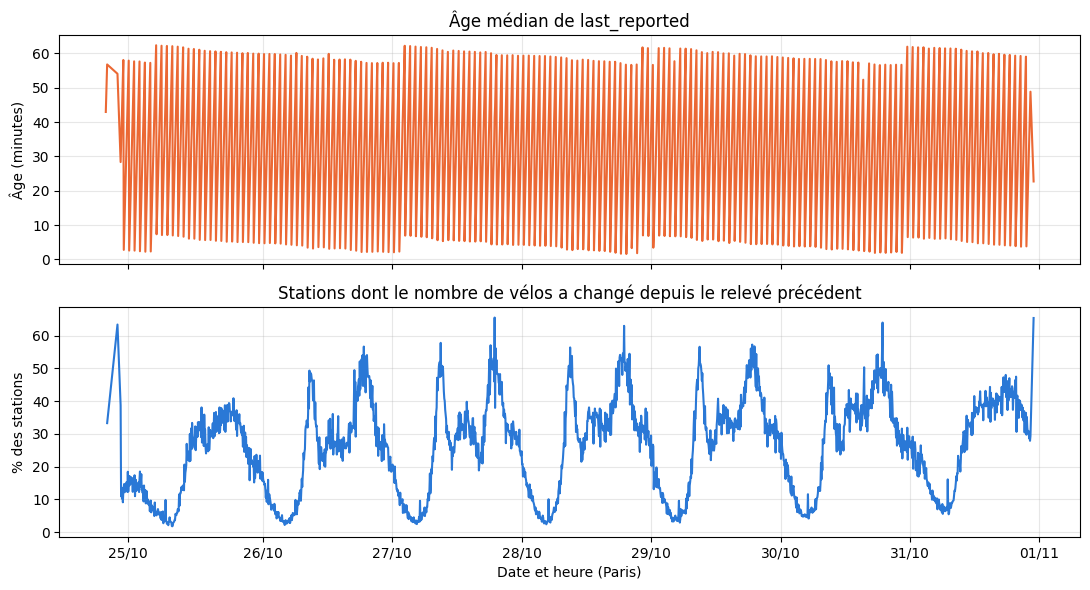

Âge médian de last_reported : 32 min
Part médiane de stations qui changent en 5 min : 28.2 %


In [ ]:
df["age_last_reported_min"] = (df["collecte"] - pd.to_datetime(df["last_reported"], unit="s", utc=True)).dt.total_seconds() / 60
age_median = df.groupby("temps")["age_last_reported_min"].median()

tableau_velos = df.pivot_table(index="temps", columns="station_id", values="velos")
part_changement = ((tableau_velos.diff() != 0).mean(axis=1) * 100).iloc[1:]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(age_median.index, age_median.values, color=ORANGE)
axes[0].set_title("Âge médian de last_reported")
axes[0].set_ylabel("Âge (minutes)")
axes[1].plot(part_changement.index, part_changement.values, color=BLEU)
axes[1].set_title("Stations dont le nombre de vélos a changé depuis le relevé précédent")
axes[1].set_ylabel("% des stations")
axes[1].set_xlabel("Date et heure (Paris)")
plt.tight_layout()
plt.show()

print(f"Âge médian de last_reported : {age_median.median():.0f} min")
print(f"Part médiane de stations qui changent en 5 min : {part_changement.median():.1f} %")

**Commentaire.** L'âge de `last_reported` monte jusqu'à environ 60 minutes puis retombe d'un coup pour toutes les stations : c'est un **signal de vie envoyé environ toutes les heures**, pas l'heure du dernier changement. Pendant ce temps, beaucoup de stations changent de nombre de vélos à chaque relevé, donc les compteurs sont bien mis à jour toutes les 5 minutes.

Conséquence : la colonne `stations_stale_over_15m` des fichiers `data/quality/` ne mesure pas la fraîcheur des données (elle vaut presque toujours 1 519). Seul un âge de plus de 24 h indique un vrai problème.

## 5. Analyse exploratoire (EDA)

**Objectif :** comprendre la répartition des vélos disponibles, repérer les tendances et décrire les différences entre stations et entre périodes.

On travaille sur les **stations en service** (`is_renting == 1`), sans les stations muettes. Quelques notions utilisées :
- **taux de remplissage** = vélos / (vélos + bornes libres), en % : 0 % = vide, 100 % = pleine ;
- **presque vide** = 2 vélos ou moins ;
- **proche de la saturation** = taux de remplissage d'au moins 90 %.

⚠ Les chiffres cités dans les commentaires correspondent à l'exécution du 25/10 (environ 19 h de données). Les graphiques et tableaux se mettent à jour à chaque exécution : relire les commentaires après la dernière.

In [ ]:
JOURS = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]

en_service = df[df["en_service"] == 1].copy()
en_service["taux_remplissage"] = en_service["velos"] / (en_service["velos"] + en_service["bornes_libres"]).replace(0, np.nan) * 100
en_service["presque_vide"] = (en_service["velos"] <= 2).astype(int)
en_service["presque_pleine"] = (en_service["taux_remplissage"] >= 90).astype(int)
# Si le détail mécanique/électrique manque (NaN), on laisse NaN pour ne pas fausser les moyennes.
en_service["sans_elec"] = (en_service["velos_elec"] == 0).astype(float).where(en_service["velos_elec"].notna())
en_service["sans_meca"] = (en_service["velos_meca"] == 0).astype(float).where(en_service["velos_meca"].notna())

heure_paris = en_service["temps"].dt.tz_convert("Europe/Paris")
en_service["heure"] = heure_paris.dt.hour
en_service["date"] = heure_paris.dt.date
en_service["jour"] = heure_paris.dt.dayofweek.map(lambda j: JOURS[j]) + " " + heure_paris.dt.strftime("%d/%m")
print("Observations (station × relevé) :", len(en_service))

Observations (station × relevé) : 2947828


### 5.1 Statistiques descriptives

In [ ]:
stats = en_service[["velos", "velos_meca", "velos_elec", "bornes_libres", "taux_remplissage", "capacity"]].describe().T
stats = stats.rename(columns={"count": "nb", "mean": "moyenne", "std": "écart-type", "min": "min",
                              "25%": "Q1", "50%": "médiane", "75%": "Q3", "max": "max"})
stats.index = ["Vélos disponibles (vélos)", "Vélos mécaniques (vélos)", "Vélos électriques (vélos)",
               "Bornes libres (bornes)", "Taux de remplissage (%)", "Capacité officielle (bornes)"]
stats.round(1)

,nb,moyenne,écart-type,min,Q1,médiane,Q3,max
Vélos disponibles (vélos),2947828.0,12.6,11.5,0.0,4.0,9.0,18.0,82.0
Vélos mécaniques (vélos),2920309.0,7.7,9.6,0.0,1.0,4.0,11.0,71.0
Vélos électriques (vélos),2920309.0,4.9,5.2,0.0,1.0,3.0,7.0,72.0
Bornes libres (bornes),2947828.0,18.7,12.2,0.0,9.0,17.0,26.0,78.0
Taux de remplissage (%),2947828.0,40.1,30.3,0.0,13.3,33.3,64.0,100.0
Capacité officielle (bornes),2947828.0,32.2,12.0,0.0,23.0,30.0,38.0,78.0


**Commentaire.**
- Une station a en moyenne **12,7 vélos**, mais la médiane n'est que de **9** : la distribution est asymétrique. Beaucoup de stations ont peu de vélos, et quelques grandes stations très remplies (jusqu'à 78 vélos) tirent la moyenne vers le haut.
- Le taux de remplissage moyen est d'environ **40 %** (médiane 32 %) : en général, les stations sont plus vides que pleines.
- Les écarts-types sont élevés (12 vélos, 32 points de remplissage) : les stations sont très différentes les unes des autres, ce que la suite de l'EDA détaille.
- Il y a en moyenne 7,7 vélos mécaniques et 5,0 électriques par station, pour une capacité moyenne de 32 bornes.

### 5.2 Distribution des vélos disponibles par station

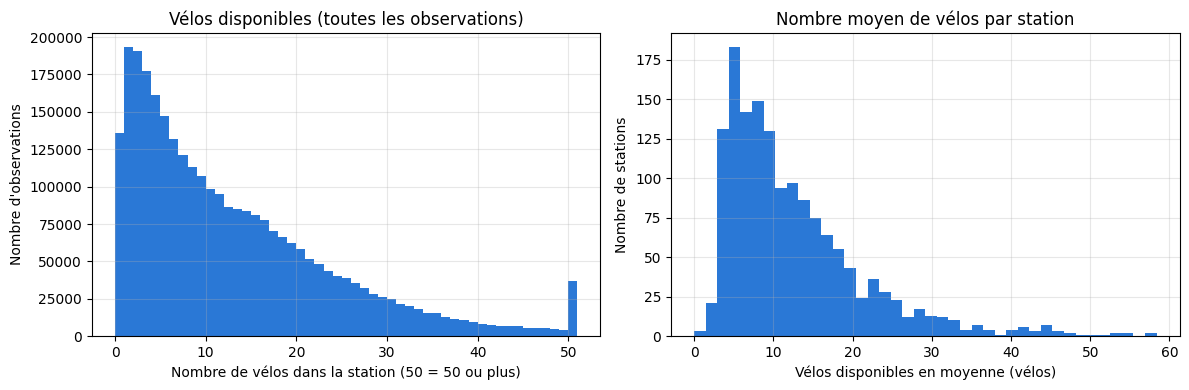

Vélos par station : moyenne 12.6, médiane 9
Observations avec 0 vélo : 4.6% | avec 2 vélos ou moins : 17.6%


In [ ]:
velos_moyens_station = en_service.groupby("station_id")["velos"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(en_service["velos"].clip(upper=50), bins=range(0, 52), color=BLEU)
axes[0].set_title("Vélos disponibles (toutes les observations)")
axes[0].set_xlabel("Nombre de vélos dans la station (50 = 50 ou plus)")
axes[0].set_ylabel("Nombre d'observations")
axes[1].hist(velos_moyens_station, bins=40, color=BLEU)
axes[1].set_title("Nombre moyen de vélos par station")
axes[1].set_xlabel("Vélos disponibles en moyenne (vélos)")
axes[1].set_ylabel("Nombre de stations")
plt.tight_layout()
plt.show()

print(f"Vélos par station : moyenne {en_service['velos'].mean():.1f}, médiane {en_service['velos'].median():.0f}")
print(f"Observations avec 0 vélo : {(en_service['velos'] == 0).mean():.1%} | avec 2 vélos ou moins : {en_service['presque_vide'].mean():.1%}")

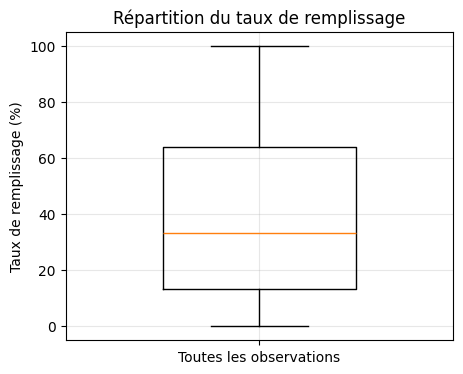

In [ ]:
plt.figure(figsize=(5, 4))
plt.boxplot(en_service["taux_remplissage"].dropna(), widths=0.5)
plt.title("Répartition du taux de remplissage")
plt.ylabel("Taux de remplissage (%)")
plt.xticks([1], ["Toutes les observations"])
plt.show()

**Commentaire.**
- L'histogramme est très asymétrique : le pic se situe entre 1 et 4 vélos. Environ **20 % des observations ont 2 vélos ou moins**, et 5 % aucun.
- La barre isolée à 50 correspond aux grandes stations très remplies (50 vélos ou plus).
- En moyenne sur la période, la majorité des stations ont moins de 10 vélos.
- Le boxplot montre que la moitié des observations ont un taux de remplissage entre 12 % et 68 % : toute la plage de 0 à 100 % est occupée, sans valeur « typique ».

### 5.3 Évolution des vélos disponibles dans le temps

Relevés sans détail mécanique/électrique : 19 sur 2025


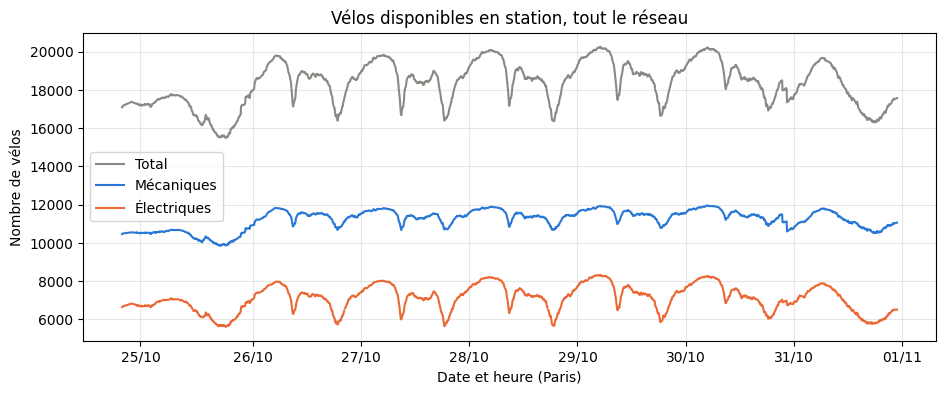

In [ ]:
total = en_service.groupby("temps")[["velos", "velos_meca", "velos_elec"]].sum(min_count=1)
# Certains relevés n'ont pas le détail mécanique/électrique (voir commentaire) : on les retire de ces courbes.
detail_ok = en_service.groupby("temps")["velos_elec"].count() > 0.9 * en_service.groupby("temps")["station_id"].count()
total.loc[~detail_ok, ["velos_meca", "velos_elec"]] = np.nan
print("Relevés sans détail mécanique/électrique :", (~detail_ok).sum(), "sur", len(detail_ok))

plt.plot(total.index, total["velos"], color=GRIS, label="Total")
plt.plot(total.index, total["velos_meca"], color=BLEU, label="Mécaniques")
plt.plot(total.index, total["velos_elec"], color=ORANGE, label="Électriques")
plt.title("Vélos disponibles en station, tout le réseau")
plt.xlabel("Date et heure (Paris)")
plt.ylabel("Nombre de vélos")
plt.legend()
plt.show()

**Commentaire.**
- Le nombre total de vélos posés en station varie peu sur la période (entre 16 000 et 17 700 environ). Il est plus haut la nuit, quand les vélos sont rangés, et baisse en fin de matinée, quand ils circulent.
- Les vélos électriques représentent environ **39 %** des vélos disponibles.
- **Anomalie :** 6 relevés de la nuit du 24 au 25 ne contiennent pas le détail mécanique/électrique (champ vide au moment de la mise à jour horaire du flux). On les retire des courbes par type, d'où les petites coupures ; le total, lui, est complet.

### 5.4 Stations vides et stations proches de la saturation

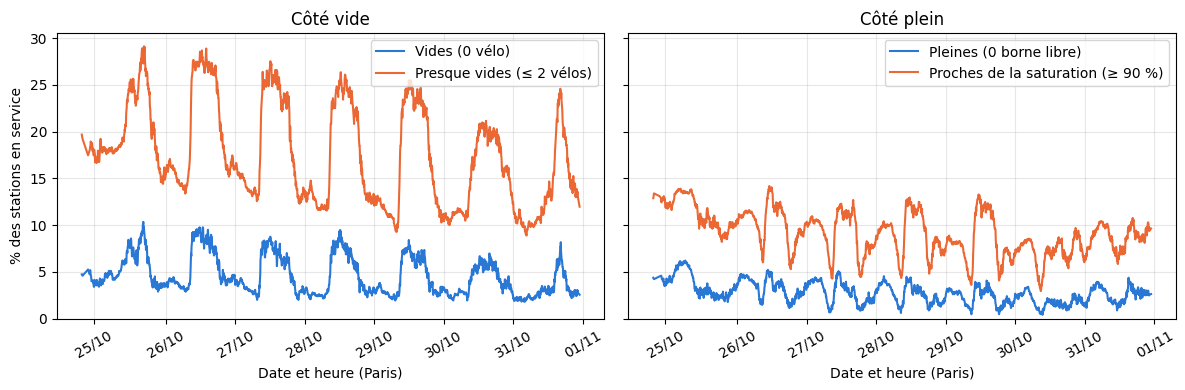

Part moyenne des stations en service (%) :
vides                                 4.6
presque vides (≤ 2 vélos)            17.6
pleines                               2.8
proches de la saturation (≥ 90 %)     9.2
dtype: float64


In [ ]:
part = en_service.groupby("temps")[["vide", "presque_vide", "pleine", "presque_pleine"]].mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
axes[0].plot(part.index, part["vide"], color=BLEU, label="Vides (0 vélo)")
axes[0].plot(part.index, part["presque_vide"], color=ORANGE, label="Presque vides (≤ 2 vélos)")
axes[0].set_title("Côté vide")
axes[1].plot(part.index, part["pleine"], color=BLEU, label="Pleines (0 borne libre)")
axes[1].plot(part.index, part["presque_pleine"], color=ORANGE, label="Proches de la saturation (≥ 90 %)")
axes[1].set_title("Côté plein")
for ax in axes:
    ax.set_xlabel("Date et heure (Paris)")
    ax.legend()
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("% des stations en service")
axes[0].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

print("Part moyenne des stations en service (%) :")
print(part.mean().round(1).rename({"vide": "vides", "presque_vide": "presque vides (≤ 2 vélos)",
                                   "pleine": "pleines", "presque_pleine": "proches de la saturation (≥ 90 %)"}))

**Commentaire.**
- Seulement **5 %** des stations sont vides en moyenne, mais **environ 20 % sont presque vides** (2 vélos ou moins) : pour un usager, une station sur cinq est à la limite de la rupture.
- Côté plein, 4 % des stations sont pleines et environ 12 % sont proches de la saturation (au moins 90 % de remplissage). Pour un usager qui veut rendre son vélo, c'est aussi un risque.
- Les deux côtés évoluent en sens inverse : en fin de matinée, les stations vides et presque vides augmentent (jusqu'à environ 25 % de presque vides) pendant que les stations pleines diminuent. Les vélos quittent les stations pour circuler.

### 5.5 Vélos mécaniques et électriques

Part des vélos électriques parmi les vélos disponibles : 38.7 % en moyenne (min 34.4 %, max 41.3 %)
Vélos par station : 7.7 mécaniques et 4.9 électriques en moyenne
Stations sans aucun vélo électrique : 13.7% | sans aucun vélo mécanique : 19.5%


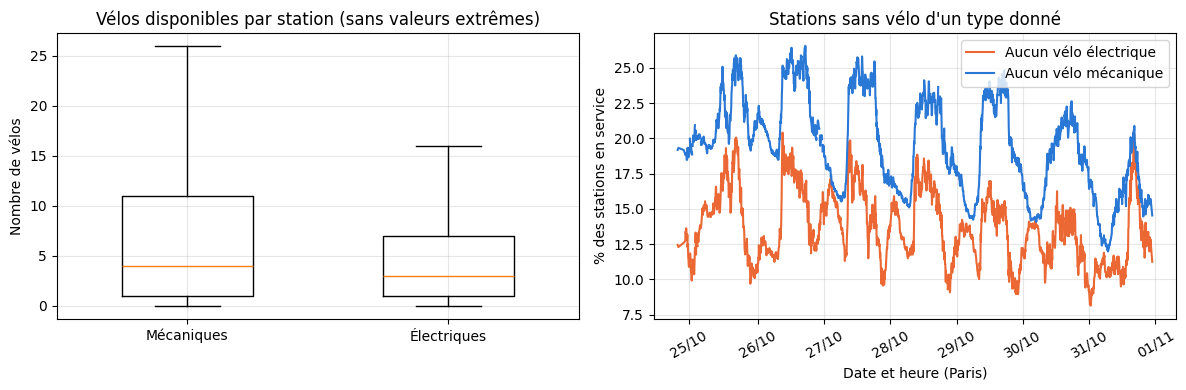

In [ ]:
total["part_elec"] = total["velos_elec"] / (total["velos_meca"] + total["velos_elec"]) * 100
print(f"Part des vélos électriques parmi les vélos disponibles : {total['part_elec'].mean():.1f} % en moyenne "
      f"(min {total['part_elec'].min():.1f} %, max {total['part_elec'].max():.1f} %)")
print(f"Vélos par station : {en_service['velos_meca'].mean():.1f} mécaniques et {en_service['velos_elec'].mean():.1f} électriques en moyenne")
print(f"Stations sans aucun vélo électrique : {en_service['sans_elec'].mean():.1%} | sans aucun vélo mécanique : {en_service['sans_meca'].mean():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
donnees = [en_service["velos_meca"].dropna(), en_service["velos_elec"].dropna()]
axes[0].boxplot(donnees, showfliers=False, widths=0.5)
axes[0].set_xticks([1, 2], ["Mécaniques", "Électriques"])
axes[0].set_title("Vélos disponibles par station (sans valeurs extrêmes)")
axes[0].set_ylabel("Nombre de vélos")

sans = en_service.groupby("temps")[["sans_elec", "sans_meca"]].mean() * 100
axes[1].plot(sans.index, sans["sans_elec"], color=ORANGE, label="Aucun vélo électrique")
axes[1].plot(sans.index, sans["sans_meca"], color=BLEU, label="Aucun vélo mécanique")
axes[1].set_title("Stations sans vélo d'un type donné")
axes[1].set_xlabel("Date et heure (Paris)")
axes[1].set_ylabel("% des stations en service")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()
plt.tight_layout()
plt.show()

**Commentaire.**
- Les vélos mécaniques sont plus nombreux (7,7 par station en moyenne contre 5,0 électriques, médianes 4 et 3).
- Pourtant, il y a **plus de stations sans aucun vélo mécanique (≈ 20 %) que sans vélo électrique (≈ 14 %)**. Les mécaniques sont plus concentrés dans certaines stations (écart-type 10,1 contre 5,5), alors que les électriques sont répartis plus uniformément.
- La part de stations sans vélo électrique augmente nettement dans la journée (de 12 % à 19 % environ) : les électriques, plus demandés, partent en premier.
- Notre cible « station vide » compte tous les vélos ensemble : une station sans électrique n'est pas vide au sens de la cible, alors qu'elle peut l'être pour un usager qui en cherche un.

### 5.6 Disponibilité selon la capacité des stations

,stations,vélos moyens (vélos),remplissage moyen (%),temps vide (%),temps pleine (%)
classe_capacite,,,,,
≤ 20 bornes,222,6.7,39.3,7.9,3.9
21 à 30,594,10.2,40.7,4.9,3.0
31 à 40,369,13.4,39.3,4.1,2.5
> 40 bornes,312,20.6,40.5,2.2,1.8


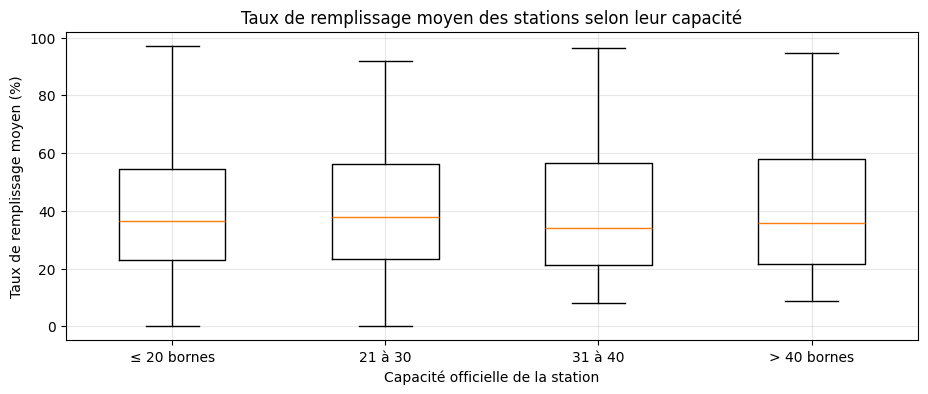

In [ ]:
en_service["classe_capacite"] = pd.cut(en_service["capacity"], bins=[0, 20, 30, 40, 1000],
                                       labels=["≤ 20 bornes", "21 à 30", "31 à 40", "> 40 bornes"])

par_classe = en_service.groupby("classe_capacite", observed=True).agg(
    stations=("station_id", "nunique"),
    velos_moyens=("velos", "mean"),
    remplissage_moyen=("taux_remplissage", "mean"),
    pct_temps_vide=("vide", "mean"),
    pct_temps_pleine=("pleine", "mean"),
)
par_classe["pct_temps_vide"] *= 100
par_classe["pct_temps_pleine"] *= 100
display(par_classe.round(1).rename(columns={
    "stations": "stations", "velos_moyens": "vélos moyens (vélos)", "remplissage_moyen": "remplissage moyen (%)",
    "pct_temps_vide": "temps vide (%)", "pct_temps_pleine": "temps pleine (%)"}))

# Un point par station : son taux de remplissage moyen.
remplissage_station = en_service.groupby("station_id").agg(remplissage=("taux_remplissage", "mean"),
                                                          classe=("classe_capacite", "first"))
classes = par_classe.index
plt.boxplot([remplissage_station.loc[remplissage_station["classe"] == c, "remplissage"].dropna() for c in classes],
            widths=0.5)
plt.xticks(range(1, len(classes) + 1), classes)
plt.title("Taux de remplissage moyen des stations selon leur capacité")
plt.xlabel("Capacité officielle de la station")
plt.ylabel("Taux de remplissage moyen (%)")
plt.show()

**Commentaire.**
- Le **taux de remplissage moyen est presque le même quelle que soit la capacité** (38 à 41 %), et les boxplots sont tous très étalés : la taille de la station n'explique pas à elle seule son remplissage.
- En revanche, **les petites stations sont plus souvent vides** : environ 8,5 % du temps pour les stations de 20 bornes ou moins, contre 3 % pour celles de plus de 40 bornes. Il faut moins de départs pour vider une petite station.
- Les grandes stations sont aussi moins souvent pleines : elles absorbent mieux les variations.

### 5.7 Variations selon l'heure et le jour

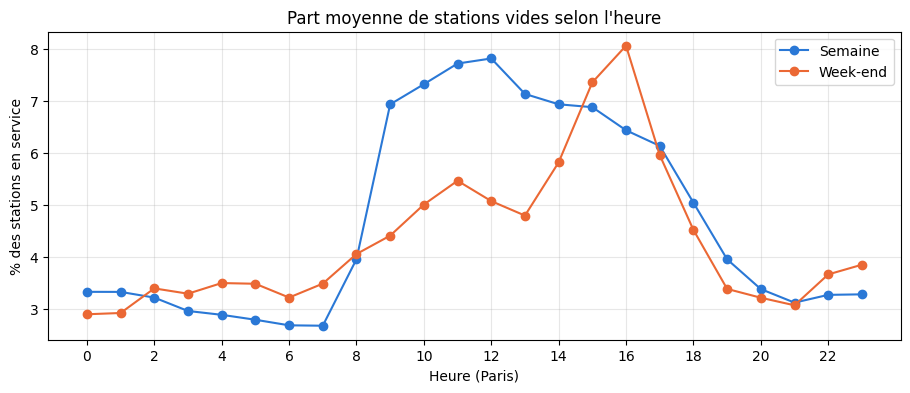

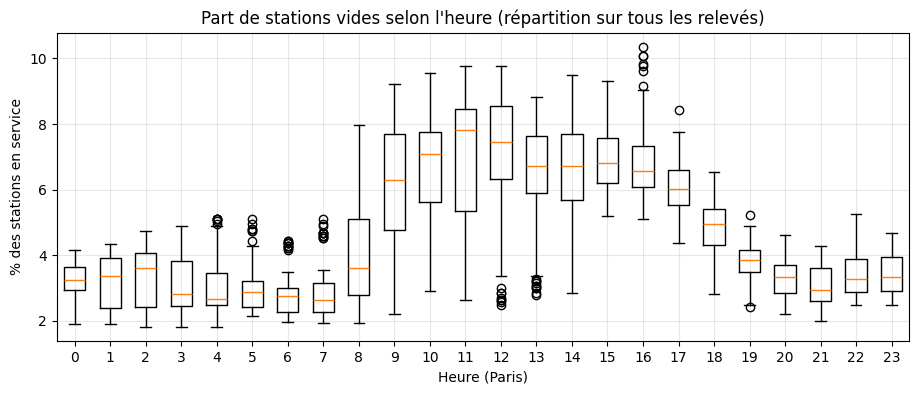

In [ ]:
part["heure"] = part.index.tz_convert("Europe/Paris").hour
part["type_jour"] = np.where(part.index.tz_convert("Europe/Paris").dayofweek >= 5, "Week-end", "Semaine")
profil = part.groupby(["heure", "type_jour"])["vide"].mean().unstack().reindex(range(24))  # heure sans donnée = trou

profil.plot(marker="o", color=[BLEU, ORANGE][: profil.shape[1]])
plt.title("Part moyenne de stations vides selon l'heure")
plt.xlabel("Heure (Paris)")
plt.ylabel("% des stations en service")
plt.xticks(range(0, 24, 2))
plt.legend(title="")
plt.show()

# Boxplot : pour chaque heure, la répartition de la part de stations vides sur tous les relevés de cette heure.
heures = sorted(part["heure"].unique())
plt.boxplot([part.loc[part["heure"] == h, "vide"] for h in heures], widths=0.6)
plt.xticks(range(1, len(heures) + 1), heures)
plt.title("Part de stations vides selon l'heure (répartition sur tous les relevés)")
plt.xlabel("Heure (Paris)")
plt.ylabel("% des stations en service")
plt.show()

,relevés (288 = jour complet),stations vides (%),stations pleines (%),remplissage moyen (%),vélos en station (moyenne)
jour,,,,,
samedi 24/10,19,4.4,4.1,40.8,17260.9
dimanche 25/10,300,5.4,3.7,39.5,16892.7
lundi 26/10,287,5.7,3.3,39.2,18568.8
mardi 27/10,288,4.9,2.8,39.6,18634.9
mercredi 28/10,288,4.6,2.6,40.0,18800.2
jeudi 29/10,287,4.4,2.3,40.3,18977.6
vendredi 30/10,286,4.0,1.9,40.3,18804.2
samedi 31/10,270,3.1,2.6,42.0,17951.2


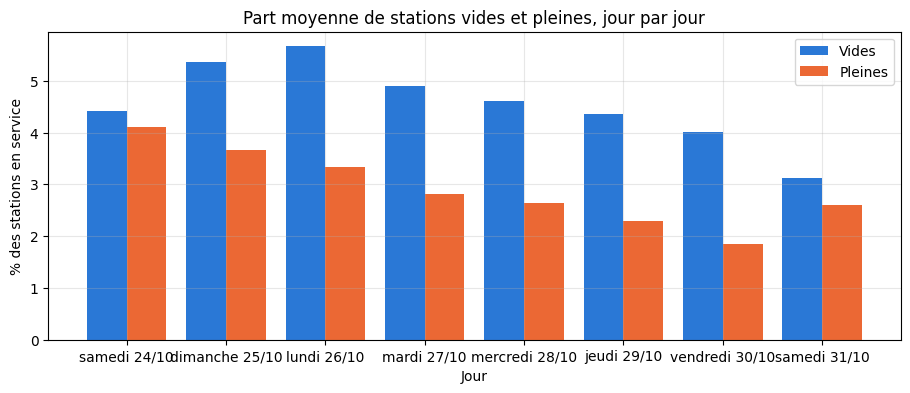

In [ ]:
# Comparaison jour par jour.
total_jour = en_service.groupby(["date", "jour", "temps"])["velos"].sum().groupby(["date", "jour"]).mean()
par_jour = en_service.groupby(["date", "jour"]).agg(releves=("temps", "nunique"),
                                                    vides=("vide", "mean"), pleines=("pleine", "mean"),
                                                    remplissage=("taux_remplissage", "mean"))
par_jour["velos_reseau"] = total_jour
par_jour["vides"] *= 100
par_jour["pleines"] *= 100
par_jour = par_jour.reset_index(level="date", drop=True)
display(par_jour.round(1).rename(columns={
    "releves": "relevés (288 = jour complet)", "vides": "stations vides (%)", "pleines": "stations pleines (%)",
    "remplissage": "remplissage moyen (%)", "velos_reseau": "vélos en station (moyenne)"}))

x = np.arange(len(par_jour))
plt.bar(x - 0.2, par_jour["vides"], width=0.4, color=BLEU, label="Vides")
plt.bar(x + 0.2, par_jour["pleines"], width=0.4, color=ORANGE, label="Pleines")
plt.xticks(x, par_jour.index)
plt.title("Part moyenne de stations vides et pleines, jour par jour")
plt.xlabel("Jour")
plt.ylabel("% des stations en service")
plt.legend()
plt.show()

**Commentaire.**
- **Selon l'heure :** la part de stations vides est minimale la nuit (environ 4 %) et monte jusqu'à environ 8 % vers 11 h. Le boxplot montre une dispersion faible la nuit et plus forte en fin de matinée, quand la situation change vite.
- Les heures de 14 h à 18 h n'ont pas encore (ou presque pas) de relevés : elles seront couvertes par la suite de la collecte.
- **Selon le jour :** pour l'instant, on n'a qu'un samedi soir partiel et un dimanche. **La comparaison semaine / week-end n'est pas encore possible** ; le tableau et le graphique se compléteront automatiquement avec les relevés jusqu'au 30 octobre.

### 5.8 Stations qui varient le plus

,station,capacité,vélos moyens,écart-type (vélos),min,max,amplitude (vélos)
1041,Pau Casals - Neuve Tolbiac,78,49.9,24.8,0,78,78
571,Assemblée Nationale,76,29.8,22.3,0,72,72
174,Gare d'Austerlitz - Pont Charles de Gaulle,75,40.9,21.0,0,73,73
1331,Gare de Lyon - Place Louis Armand,60,28.4,20.6,0,60,60
847,Malesherbes - Place de la Madeleine,67,23.0,19.9,1,67,66
1407,Gare de Lyon - Roland Barthes,68,43.5,19.8,1,68,67
1231,Tremblay - Lac des Minimes,48,31.8,19.7,8,72,64
1342,Epée de Bois - Mouffetard,63,25.8,19.4,2,61,59
1109,Gare Montparnasse - Vaugirard,66,20.3,19.4,0,63,63
1061,Cité de la Musique,60,15.5,19.3,0,81,81


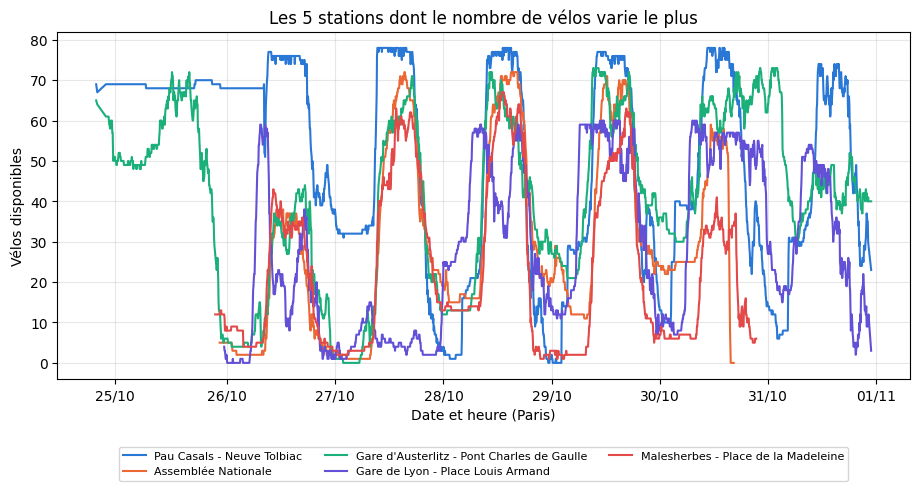

In [ ]:
variations = en_service.groupby("station_id")["velos"].agg(["mean", "std", "min", "max"])
variations["amplitude"] = variations["max"] - variations["min"]
variations = variations.merge(ref[["station_id", "name", "capacity"]], on="station_id")
top_var = variations.sort_values("std", ascending=False).head(10)

display(top_var[["name", "capacity", "mean", "std", "min", "max", "amplitude"]].round(1).rename(columns={
    "name": "station", "capacity": "capacité", "mean": "vélos moyens", "std": "écart-type (vélos)",
    "amplitude": "amplitude (vélos)"}))

plt.figure(figsize=(11, 4.5))
couleurs = [BLEU, ORANGE, "#1baf7a", "#6250d6", "#e34948"]
for station_id, couleur in zip(top_var["station_id"].head(5), couleurs):
    serie = en_service[en_service["station_id"] == station_id].set_index("temps")["velos"]
    plt.plot(serie.index, serie.values, color=couleur, label=variations.set_index("station_id").loc[station_id, "name"])
plt.title("Les 5 stations dont le nombre de vélos varie le plus")
plt.xlabel("Date et heure (Paris)")
plt.ylabel("Vélos disponibles")
plt.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.show()

**Commentaire.**
- Les stations qui varient le plus sont surtout de **grandes stations** (42 à 71 bornes), avec un écart-type d'environ 9 à 11 vélos. Certaines passent de presque vide à presque pleine dans la journée, par exemple « Stade de France » (de 0 à 44 vélos) ou « Gare RER de Vincennes » (de 2 à 38).
- On voit deux types de variations sur les courbes :
  - des **montées progressives** en fin de matinée, liées aux trajets des usagers ;
  - des **sauts brusques en pleine nuit** (par exemple plus de 20 vélos ajoutés ou retirés en quelques minutes vers 1 h–3 h). Ils correspondent très probablement à la **régulation** : des camions de l'opérateur déplacent des vélos. Ces mouvements ne sont pas prévisibles avec nos données.

### 5.9 Est-ce toujours les mêmes stations qui sont vides ?

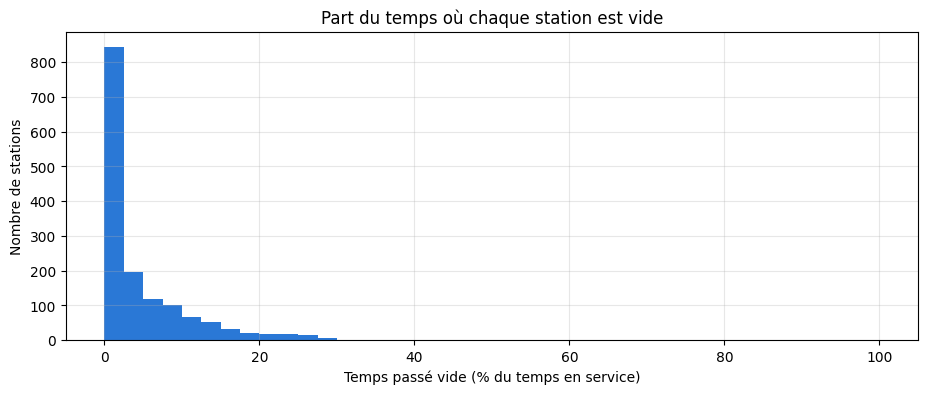

Stations jamais vides : 31%
Les 10 % de stations les plus souvent vides représentent 46% du temps vide total
Stations vides plus de 95 % du temps : 2


,station,capacité,part du temps vide
991,Place de la République - Temple,18,1.000000
564,Lacépède - Monge,23,1.000000
694,Louis Lumière - Porte de Bagnolet,20,0.495072
812,Frères Flavien - Porte des Lilas,23,0.394568
721,Lassus - Delouvain,20,0.353086
533,Haxo - Darcy,22,0.328395
1136,Gambetta - Tourelles,20,0.313086
529,Tourlaque - Damrémont,16,0.303210
500,Place des Fêtes - Solitaires,29,0.298272
1065,Belleville - Pré Saint-Gervais,35,0.296296


In [ ]:
par_station = en_service.groupby("station_id")["vide"].mean().to_frame("part_temps_vide")
par_station = par_station.merge(ref, on="station_id", how="left")

plt.hist(par_station["part_temps_vide"] * 100, bins=40, color=BLEU)
plt.title("Part du temps où chaque station est vide")
plt.xlabel("Temps passé vide (% du temps en service)")
plt.ylabel("Nombre de stations")
plt.show()

tri = par_station.sort_values("part_temps_vide", ascending=False)
top10 = tri.head(len(tri) // 10)
print(f"Stations jamais vides : {(par_station['part_temps_vide'] == 0).mean():.0%}")
print(f"Les 10 % de stations les plus souvent vides représentent {top10['part_temps_vide'].sum() / tri['part_temps_vide'].sum():.0%} du temps vide total")
print(f"Stations vides plus de 95 % du temps : {(par_station['part_temps_vide'] > 0.95).sum()}")
tri.head(10)[["name", "capacity", "part_temps_vide"]].rename(columns={"name": "station", "capacity": "capacité",
                                                                     "part_temps_vide": "part du temps vide"})

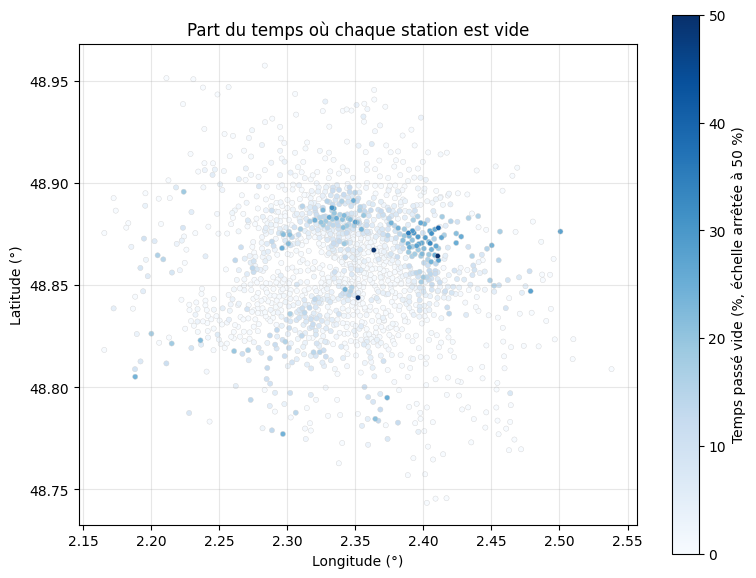

In [ ]:
carte = par_station.sort_values("part_temps_vide")   # les stations souvent vides sont dessinées par-dessus
plt.figure(figsize=(9, 7))
plt.scatter(carte["lon"], carte["lat"], c=carte["part_temps_vide"] * 100,
            cmap="Blues", s=14, vmax=50, edgecolors="lightgray", linewidths=0.3)
plt.colorbar(label="Temps passé vide (%, échelle arrêtée à 50 %)")
plt.title("Part du temps où chaque station est vide")
plt.xlabel("Longitude (°)")
plt.ylabel("Latitude (°)")
plt.gca().set_aspect(1.5)   # pour que Paris ne soit pas écrasé
plt.show()

**Commentaire.**
- Les stations vides sont presque toujours les mêmes : environ **70 % des stations ne sont jamais vides**, et les 10 % les plus touchées représentent environ **76 % du temps vide** total.
- **Anomalie :** certaines stations sont vides en permanence tout en étant « en service » (Lacépède – Monge : 100 % du temps). Elles sont sans doute en panne.
- Sur la carte, les stations souvent vides forment des groupes, notamment sur les hauteurs (Montmartre, Belleville–Ménilmontant) : on y descend à vélo mais on remonte rarement. À vérifier sur la semaine complète.
- Pour le modèle, l'historique de chaque station sera donc une variable utile.

### 5.10 Tableau de synthèse des indicateurs descriptifs

In [ ]:
synthese = pd.DataFrame([
    ("Période observée", f"{debut.tz_convert('Europe/Paris'):%d/%m %H:%M} → {fin.tz_convert('Europe/Paris'):%d/%m %H:%M}", ""),
    ("Durée de collecte", round(duree_heures, 1), "heures"),
    ("Relevés obtenus / attendus", f"{len(releves)} / {attendus}", "relevés"),
    ("Stations analysées", df["station_id"].nunique(), "stations"),
    ("Stations hors service (en moyenne)", round((1 - df.groupby("temps")["en_service"].mean().mean()) * 100, 1), "%"),
    ("Vélos disponibles dans le réseau (moyenne)", round(total["velos"].mean()), "vélos"),
    ("Part de vélos électriques", round(total["part_elec"].mean(), 1), "%"),
    ("Vélos par station (moyenne)", round(en_service["velos"].mean(), 1), "vélos"),
    ("Vélos par station (médiane)", en_service["velos"].median(), "vélos"),
    ("Taux de remplissage moyen", round(en_service["taux_remplissage"].mean(), 1), "%"),
    ("Stations vides", round(part["vide"].mean(), 1), "% des stations"),
    ("Stations presque vides (≤ 2 vélos)", round(part["presque_vide"].mean(), 1), "% des stations"),
    ("Stations pleines", round(part["pleine"].mean(), 1), "% des stations"),
    ("Stations proches de la saturation (≥ 90 %)", round(part["presque_pleine"].mean(), 1), "% des stations"),
    ("Stations sans vélo électrique", round(en_service["sans_elec"].mean() * 100, 1), "% des stations"),
    ("Stations jamais vides sur la période", round((par_station["part_temps_vide"] == 0).mean() * 100, 1), "% des stations"),
    ("Stations vides plus de 95 % du temps", int((par_station["part_temps_vide"] > 0.95).sum()), "stations"),
], columns=["indicateur", "valeur", "unité"])
synthese

,indicateur,valeur,unité
0,Période observée,24/10 19:55 → 31/10 22:55,
1,Durée de collecte,172.0,heures
2,Relevés obtenus / attendus,2025 / 2065,relevés
3,Stations analysées,1502,stations
4,Stations hors service (en moyenne),3.0,%
5,Vélos disponibles dans le réseau (moyenne),18359,vélos
6,Part de vélos électriques,38.7,%
7,Vélos par station (moyenne),12.6,vélos
8,Vélos par station (médiane),9.0,vélos
9,Taux de remplissage moyen,40.1,%


### Principales tendances et anomalies

**Tendances**
1. Les stations sont en général **plus vides que pleines** (remplissage médian ≈ 32 %), avec une distribution très asymétrique.
2. Peu de stations sont vides à un instant donné (≈ 5 %), mais **une sur cinq est presque vide** : le risque pour l'usager est plus large que les seules ruptures.
3. Les ruptures sont **concentrées** : peu de stations, toujours les mêmes, souvent regroupées géographiquement, et plus fréquentes dans les **petites stations**.
4. Il y a un **cycle quotidien** : les stations se remplissent la nuit et se vident en journée.
5. Les **vélos électriques** (≈ 39 % des vélos disponibles) sont mieux répartis mais partent en premier dans la journée.

**Anomalies**
- 18 stations muettes depuis plus de 24 h (dont une déclarée en service), retirées de l'analyse ;
- des stations vides en permanence alors qu'elles sont « en service » ;
- « vélos + bornes libres » inférieur à la capacité environ la moitié du temps : bornes hors service ;
- quelques relevés sans détail mécanique/électrique ;
- `last_reported` qui n'est qu'un signal de vie horaire ;
- des sauts brusques la nuit, dus très probablement à la régulation ;
- des trous de collecte au démarrage du workflow.

**Limites liées à la durée de collecte**
- Les chiffres cités dans les commentaires viennent de l'exécution du 25/10, sur environ 19 h (samedi soir et dimanche). Ils sont à vérifier après la dernière exécution.
- Même avec la collecte complète (≈ 6 jours fin octobre), les profils par heure et par jour reposent sur peu de jours : ils montrent des tendances, pas des moyennes stables. Aucune conclusion n'est possible sur les saisons, la météo, les vacances ou les événements.

## 6. Construction de la cible « vide dans 30 min »

Pour chaque station et chaque instant *t*, on va chercher l'état de la même station à *t* + 30 min avec un `merge`. On ajoute aussi des variables du passé (nombre de vélos il y a 15 et 30 minutes) pour mesurer si la station est en train de se vider. On n'utilise **jamais** d'information postérieure à *t* comme variable.

In [ ]:
def decaler(df, minutes, suffixe):
    """Renvoie les vélos et l'état de service décalés dans le temps, pour les fusionner avec df."""
    copie = df[["station_id", "temps", "velos", "en_service"]].copy()
    copie["temps"] = copie["temps"] - pd.Timedelta(minutes=minutes)
    return copie.rename(columns={"velos": "velos" + suffixe, "en_service": "en_service" + suffixe})


# État dans 30 minutes (pour la cible)
data = df.merge(decaler(df, 30, "_futur"), on=["station_id", "temps"], how="inner")

# État il y a 15 et 30 minutes (variables explicatives)
data = data.merge(decaler(df, -15, "_moins15"), on=["station_id", "temps"], how="left")
data = data.merge(decaler(df, -30, "_moins30"), on=["station_id", "temps"], how="left")

# On garde les stations en service maintenant et dans 30 minutes.
data = data[(data["en_service"] == 1) & (data["en_service_futur"] == 1)].copy()
data["cible"] = (data["velos_futur"] == 0).astype(int)

print("Nombre d'exemples :", len(data))
print(f"Part de stations vides dans 30 min : {data['cible'].mean():.1%}")

Nombre d'exemples : 2927447
Part de stations vides dans 30 min : 4.6%


In [ ]:
# Variables explicatives
data["vide_maintenant"] = (data["velos"] == 0).astype(int)
data["taux_remplissage"] = data["velos"] / (data["velos"] + data["bornes_libres"]).replace(0, np.nan)
data["variation_15min"] = data["velos"] - data["velos_moins15"]
data["variation_30min"] = data["velos"] - data["velos_moins30"]
data["heure"] = data["temps"].dt.tz_convert("Europe/Paris").dt.hour
data["week_end"] = (data["temps"].dt.tz_convert("Europe/Paris").dt.dayofweek >= 5).astype(int)
data = data.merge(ref[["station_id", "lat", "lon"]], on="station_id", how="left")
data = data.dropna(subset=["lat", "lon"])

# Valeurs manquantes (relevé passé absent) : on remplace par 0 (pas de variation connue).
for col in ["taux_remplissage", "variation_15min", "variation_30min", "velos_elec"]:
    data[col] = data[col].fillna(0)

In [ ]:
# Tableau clé : que devient une station 30 minutes plus tard ?
pd.crosstab(data["vide_maintenant"], data["cible"], normalize="index").round(3) * 100

cible,0,1
vide_maintenant,,
0,98.1,1.9
1,38.9,61.1


**Commentaire.** Ce tableau résume le problème :
- une station **vide maintenant** l'est encore dans 30 minutes dans la grande majorité des cas ;
- une station **qui a des vélos** ne devient vide que dans une petite fraction des cas.

Il faut donc comparer nos modèles à une règle très simple, la **persistance** : « si la station est vide maintenant, elle sera vide dans 30 min ». La vraie difficulté est de prévoir les stations qui ont encore des vélos mais vont se vider. Comme les stations vides sont rares, l'accuracy n'a pas de sens ici (prédire « jamais vide » donnerait plus de 90 %) : on utilise la précision, le rappel, le F1 et la PR-AUC.

## 7. Modèles et évaluation

**Découpage dans l'ordre du temps.** On coupe la période en trois morceaux successifs :
- **entraînement** (60 % du temps) : pour apprendre les modèles ;
- **validation** (15 %) : pour choisir le seuil de décision ;
- **test** (25 % restants) : pour l'évaluation finale, utilisé une seule fois.

On ne mélange pas au hasard : deux relevés espacés de 5 minutes se ressemblent presque toujours, un découpage aléatoire donnerait donc des scores trop optimistes. On laisse aussi un écart de 30 minutes avant chaque coupure, pour que la cible d'une période ne tombe pas dans la période suivante.

In [ ]:
t_debut = data["temps"].min()
duree = data["temps"].max() - t_debut
marge = pd.Timedelta(minutes=30)
coupure_valid = t_debut + 0.60 * duree
coupure_test = t_debut + 0.75 * duree

train = data[data["temps"] < coupure_valid - marge].copy()
valid = data[(data["temps"] >= coupure_valid) & (data["temps"] < coupure_test - marge)].copy()
test = data[data["temps"] >= coupure_test].copy()

for nom, partie in [("Entraînement", train), ("Validation", valid), ("Test", test)]:
    print(f"{nom:13}: {partie['temps'].min().tz_convert('Europe/Paris'):%d/%m %H:%M} → "
          f"{partie['temps'].max().tz_convert('Europe/Paris'):%d/%m %H:%M} | {len(partie)} lignes | "
          f"{partie['cible'].mean():.1%} de positifs")

Entraînement : 24/10 22:40 → 29/10 02:00 | 1755059 lignes | 5.1% de positifs
Validation   : 29/10 02:35 → 30/10 03:15 | 441870 lignes | 4.2% de positifs
Test         : 30/10 03:50 → 31/10 21:50 | 712548 lignes | 3.7% de positifs


In [ ]:
# Historique de chaque station : part du temps vide, calculée SEULEMENT sur l'entraînement.
historique = train.groupby("station_id")["vide_maintenant"].mean()
for partie in [train, valid, test]:
    partie["historique_station"] = partie["station_id"].map(historique).fillna(historique.mean())

variables = ["velos", "bornes_libres", "velos_elec", "taux_remplissage", "variation_15min",
             "variation_30min", "heure", "week_end", "historique_station", "lat", "lon"]

X_test, y_test = test[variables], test["cible"]

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
                             precision_recall_curve, confusion_matrix)

# Pour que l'entraînement reste rapide sur Colab, on prend au plus 300 000 lignes au hasard.
echantillon = train.sample(min(len(train), 300_000), random_state=0)

modele_lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
modele_lr.fit(echantillon[variables], echantillon["cible"])

modele_rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=20,
                                   n_jobs=-1, random_state=0)
modele_rf.fit(echantillon[variables], echantillon["cible"])
print("Modèles entraînés")

Modèles entraînés


In [ ]:
# Choix du seuil sur la validation.
# Par défaut, predict() prédit "vide" si la probabilité dépasse 0,5. Comme les stations vides sont rares,
# ce seuil est trop strict : on teste plusieurs seuils et on garde celui qui donne le meilleur F1.
seuils = [0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.5]
modeles = {"Régression logistique": modele_lr, "Random forest": modele_rf}
meilleur_seuil = {}
tableau_seuils = pd.DataFrame(index=seuils)

for nom, modele in modeles.items():
    proba_valid = modele.predict_proba(valid[variables])[:, 1]
    tableau_seuils[nom] = [f1_score(valid["cible"], proba_valid >= s) for s in seuils]
    meilleur_seuil[nom] = float(tableau_seuils[nom].idxmax())

print("F1 sur la validation selon le seuil :")
display(tableau_seuils.round(3))
print("Seuils retenus :", meilleur_seuil)

F1 sur la validation selon le seuil :


,Régression logistique,Random forest
0.10,0.469,0.507
0.15,0.507,0.551
0.20,0.546,0.579
0.25,0.568,0.598
0.30,0.581,0.600
0.35,0.585,0.593
0.40,0.559,0.584
0.50,0.457,0.554


Seuils retenus : {'Régression logistique': 0.35, 'Random forest': 0.3}


In [ ]:
def evaluer(nom, y_vrai, y_pred, proba=None):
    resultat = {
        "modèle": nom,
        "précision": precision_score(y_vrai, y_pred, zero_division=0),
        "rappel": recall_score(y_vrai, y_pred, zero_division=0),
        "F1": f1_score(y_vrai, y_pred, zero_division=0),
    }
    if proba is not None:
        resultat["PR-AUC"] = average_precision_score(y_vrai, proba)
    return resultat


predictions = {"Persistance": (test["vide_maintenant"].to_numpy(), None)}
for nom, modele in modeles.items():
    proba_test = modele.predict_proba(X_test)[:, 1]
    predictions[nom] = ((proba_test >= meilleur_seuil[nom]).astype(int), proba_test)

# Résultats sur tout le test
resultats = pd.DataFrame([evaluer(nom, y_test, pred, proba) for nom, (pred, proba) in predictions.items()])
print("Toutes les stations du test :")
display(resultats.round(3))

# Résultats sur les stations qui ont encore des vélos : peut-on prévoir qu'elles vont se vider ?
non_vides = (test["vide_maintenant"] == 0).to_numpy()
resultats_non_vides = pd.DataFrame([
    evaluer(nom, y_test[non_vides], pred[non_vides], None if proba is None else proba[non_vides])
    for nom, (pred, proba) in predictions.items()
])
print("Stations qui ont encore des vélos maintenant :")
display(resultats_non_vides.round(3))

Toutes les stations du test :


,modèle,précision,rappel,F1,PR-AUC
0,Persistance,0.565,0.560,0.563,NaN
1,Régression logistique,0.532,0.552,0.542,0.515
2,Random forest,0.549,0.570,0.559,0.580


Stations qui ont encore des vélos maintenant :


,modèle,précision,rappel,F1,PR-AUC
0,Persistance,0.000,0.000,0.000,NaN
1,Régression logistique,0.189,0.055,0.085,0.159
2,Random forest,0.292,0.073,0.116,0.189


In [ ]:
# Matrice de confusion du random forest
pd.DataFrame(confusion_matrix(y_test, predictions["Random forest"][0]),
             index=["réel : pas vide", "réel : vide"], columns=["prédit : pas vide", "prédit : vide"])

,prédit : pas vide,prédit : vide
réel : pas vide,673718,12398
réel : vide,11364,15068


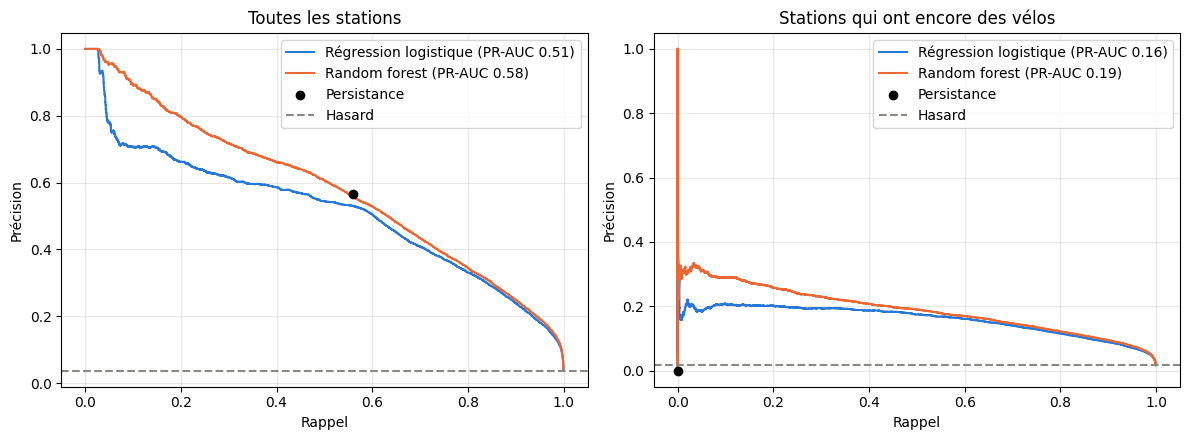

In [ ]:
# Courbes précision-rappel : on voit tous les compromis possibles, pas seulement le seuil 0,5.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, masque, titre in [(axes[0], np.ones(len(y_test), dtype=bool), "Toutes les stations"),
                          (axes[1], non_vides, "Stations qui ont encore des vélos")]:
    for nom, couleur in [("Régression logistique", BLEU), ("Random forest", ORANGE)]:
        proba = predictions[nom][1][masque]
        precision, rappel, _ = precision_recall_curve(y_test[masque], proba)
        ax.plot(rappel, precision, color=couleur, label=f"{nom} (PR-AUC {average_precision_score(y_test[masque], proba):.2f})")
    p = precision_score(y_test[masque], test["vide_maintenant"][masque], zero_division=0)
    r = recall_score(y_test[masque], test["vide_maintenant"][masque], zero_division=0)
    ax.scatter(r, p, color="black", zorder=3, label="Persistance")
    ax.axhline(y_test[masque].mean(), color=GRIS, linestyle="--", label="Hasard")
    ax.set_title(titre)
    ax.set_xlabel("Rappel")
    ax.set_ylabel("Précision")
    ax.legend()
plt.tight_layout()
plt.show()

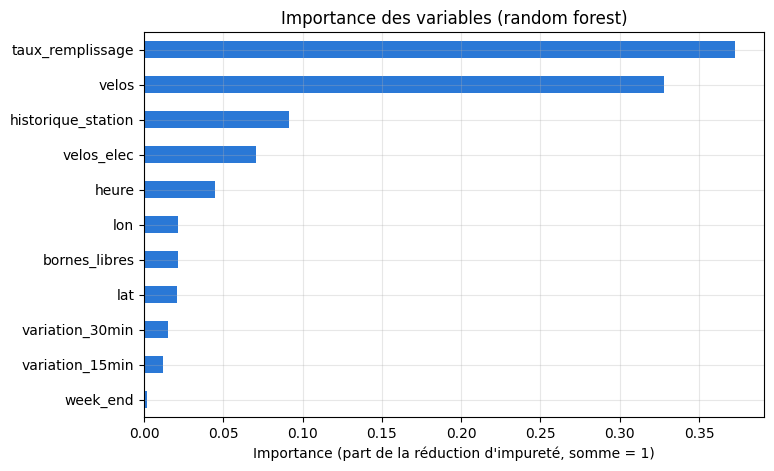

In [ ]:
# Importance des variables (random forest)
importance = pd.Series(modele_rf.feature_importances_, index=variables).sort_values()
importance.plot(kind="barh", color=BLEU, figsize=(8, 5))
plt.title("Importance des variables (random forest)")
plt.xlabel("Importance (part de la réduction d'impureté, somme = 1)")
plt.show()

**Commentaire.**
- Sur **toutes les stations**, la persistance est déjà très forte, car une station vide le reste souvent plus de 30 minutes. Si un modèle ne fait pas mieux qu'elle, il n'apporte rien.
- Sur les **stations qui ont encore des vélos**, la persistance ne détecte aucune rupture (rappel = 0). C'est là que les modèles sont utiles : ils repèrent une partie des stations qui vont se vider, avec une précision bien meilleure que le hasard (ligne pointillée).
- Le seuil de décision a été choisi sur la validation. La courbe précision-rappel montre tous les autres compromis possibles : baisser le seuil détecte plus de ruptures, au prix de plus de fausses alertes. Le bon choix dépend de l'usage (une appli qui prévient l'usager préférera peu de fausses alertes).
- Si les modèles font moins bien que la persistance en F1 sur toutes les stations, c'est souvent parce que la validation est courte et ne ressemble pas au test (heures différentes) : le seuil choisi se transpose mal.
- Les variables les plus importantes sont le nombre de vélos restants (et le taux de remplissage) et l'historique de la station. Sur les premières données, la tendance récente (variation sur 15 et 30 min) compte peu : à revoir avec la semaine complète, où les heures de pointe devraient la rendre plus utile.

⚠ Avec peu de jours de données, l'entraînement ne couvre pas toutes les heures de la journée : les résultats peuvent changer nettement avec la semaine complète. Relire ces commentaires après la dernière exécution.

## 8. Conclusion et limites

In [ ]:
# Chiffres clés, recalculés à chaque exécution (à reprendre dans le rapport).
print(f"Période : {debut.tz_convert('Europe/Paris'):%d/%m %H:%M} → {fin.tz_convert('Europe/Paris'):%d/%m %H:%M}, {duree_heures:.0f} h, couverture {len(releves) / attendus:.0%}")
print(f"Stations analysées : {df['station_id'].nunique()} ({len(muettes)} stations muettes retirées)")
print(f"Stations vides en moyenne : {part['vide'].mean():.1f} %")
print(f"Stations jamais vides : {(par_station['part_temps_vide'] == 0).mean():.0%}")
print(f"Vide dans 30 min si vide maintenant : {data.loc[data['vide_maintenant'] == 1, 'cible'].mean():.0%} ; si non vide : {data.loc[data['vide_maintenant'] == 0, 'cible'].mean():.1%}")
print()
print(resultats.set_index("modèle").round(2))
print()
print(resultats_non_vides.set_index("modèle").round(2))

Période : 24/10 19:55 → 31/10 22:55, 172 h, couverture 98%
Stations analysées : 1502 (18 stations muettes retirées)
Stations vides en moyenne : 4.6 %
Stations jamais vides : 31%
Vide dans 30 min si vide maintenant : 61% ; si non vide : 1.9%

                       précision  rappel    F1  PR-AUC
modèle                                                
Persistance                 0.56    0.56  0.56     NaN
Régression logistique       0.53    0.55  0.54    0.51
Random forest               0.55    0.57  0.56    0.58

                       précision  rappel    F1  PR-AUC
modèle                                                
Persistance                 0.00    0.00  0.00     NaN
Régression logistique       0.19    0.05  0.09    0.16
Random forest               0.29    0.07  0.12    0.19


### Conclusion

1. **La collecte fonctionne** : environ un relevé toutes les 5 minutes, avec quelques trous documentés. Les compteurs de vélos sont fiables ; seul `last_reported` est trompeur.
2. **Les stations vides sont rares et concentrées** : quelques pourcents des stations à un instant donné, presque toujours les mêmes, regroupées géographiquement.
3. **La persistance est difficile à battre** sur les stations déjà vides, car les ruptures durent souvent plus de 30 minutes.
4. **Les modèles servent surtout à anticiper** les ruptures des stations qui ont encore quelques vélos, surtout grâce au nombre de vélos restants et à l'historique de la station.

### Limites

- **Période courte** : environ une semaine en octobre. Pas de conclusion possible sur les saisons, la météo ou les vacances.
- **Trous de collecte** : le cron GitHub n'est pas garanti ; les relevés manqués sont perdus.
- **Un seul découpage** entraînement/validation/test : il faudrait répéter l'évaluation sur plusieurs jours pour voir si les scores sont stables.
- **Définition de « vide »** : on compte tous les vélos ensemble. Une station sans vélo électrique mais avec des mécaniques n'est pas vide pour nous, alors qu'elle peut l'être pour un usager.
- **Capacité** : la capacité officielle ne tient pas compte des bornes en panne.
- **Redistribution** : les camions de l'opérateur déplacent des vélos, ce qui crée des changements brusques impossibles à prévoir avec ces données.

**Source** : flux GBFS Vélib' Métropole (`station_status.json` et `station_information.json`), [documentation open data](https://www.velib-metropole.fr/fr/donnees-open-data-gbfs-du-service-velib-metropole).

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# On prédit le nombre de vélos dans 30 minutes
cible = "velos_futur"

modele = RandomForestRegressor(n_estimators=100, random_state=0)
modele.fit(echantillon[variables], echantillon[cible])

print("Modèle entraîné")

Modèle entraîné


In [ ]:
# Prédictions du modèle
prediction = modele.predict(X_test)

# On interdit les nombres négatifs
prediction = prediction.clip(min=0)

# Règle simple : le nombre de vélos ne change pas
prediction_simple = test["velos"]

# Vraie valeur à prédire
vrai = test[cible]

print("Erreur moyenne du modèle :", round(mean_absolute_error(vrai, prediction), 2), "vélos")
print("Erreur moyenne de la règle simple :", round(mean_absolute_error(vrai, prediction_simple), 2), "vélos")

Erreur moyenne du modèle : 1.45 vélos
Erreur moyenne de la règle simple : 1.31 vélos


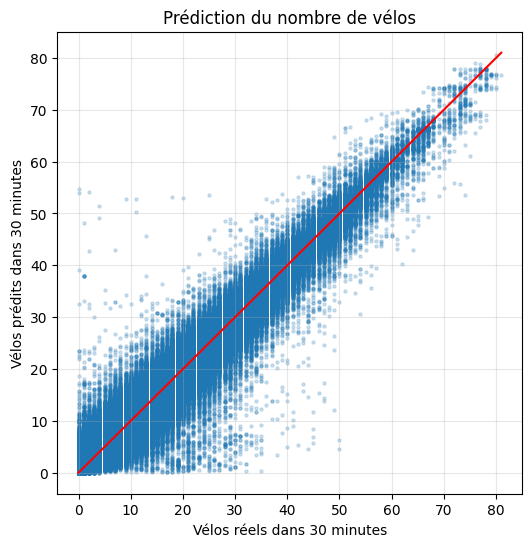

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(vrai, prediction, alpha=0.2, s=5)
plt.plot([0, vrai.max()], [0, vrai.max()], color="red")
plt.xlabel("Vélos réels dans 30 minutes")
plt.ylabel("Vélos prédits dans 30 minutes")
plt.title("Prédiction du nombre de vélos")
plt.show()

In [ ]:
# On garde une ligne par station du test
resultats_stations = test[["station_id", "velos", "velos_futur"]].copy()

resultats_stations["velos_predits"] = prediction

resultats_stations["erreur"] = (
    resultats_stations["velos_predits"] - resultats_stations["velos_futur"]
)

resultats_stations["erreur_absolue"] = resultats_stations["erreur"].abs()

resultats_stations.head()

,station_id,velos,velos_futur,velos_predits,erreur,erreur_absolue
2216123,11908496227,15,15,14.984000,-0.016000,0.016000
2216124,49423507,40,40,46.147500,6.147500,6.147500
2216125,128834707,3,2,1.933000,-0.067000,0.067000
2216126,15290700,15,15,15.538333,0.538333,0.538333
2216127,391845823,15,15,15.221024,0.221024,0.221024


#les 10 stations qui vont avoir le moins de vélos


In [ ]:
prochaines_vides = (
    resultats_stations
    .sort_values("velos_predits")
    .drop_duplicates("station_id")
    .head(10)
)

prochaines_vides[["station_id", "velos", "velos_futur", "velos_predits"]]

,station_id,velos,velos_futur,velos_predits
2706813,210403080,0,0,0.0
2264857,27414841,0,0,0.0
2638395,213695073,0,0,0.0
2422256,221047138,0,0,0.0
2253671,129029327,0,0,0.0
2229783,66491366,0,0,0.0
2376881,442739463,0,0,0.0
2254636,20636368032,0,0,0.0
2502877,6352,0,0,0.0
2232984,36151,0,0,0.0


#nombre prédit pour une station précise

In [ ]:
station_choisie = "213688169"

station = resultats_stations[
    resultats_stations["station_id"] == station_choisie
]

print("Nombre de prédictions :", len(station))
print("Vélos actuels en moyenne :", round(station["velos"].mean(), 1))
print("Vélos réels dans 30 min en moyenne :", round(station["velos_futur"].mean(), 1))
print("Vélos prédits dans 30 min en moyenne :", round(station["velos_predits"].mean(), 1))
print("Erreur absolue moyenne :", round(station["erreur_absolue"].mean(), 1), "vélos")

Nombre de prédictions : 501
Vélos actuels en moyenne : 17.5
Vélos réels dans 30 min en moyenne : 17.5
Vélos prédits dans 30 min en moyenne : 17.5
Erreur absolue moyenne : 1.0 vélos


In [ ]:
station[["velos", "velos_futur", "velos_predits", "erreur"]].head(10)

,velos,velos_futur,velos_predits,erreur
2217246,19,19,19.288667,0.288667
2218625,19,19,19.288667,0.288667
2220125,19,19,19.305939,0.305939
2221624,19,19,19.305939,0.305939
2223242,19,19,19.305939,0.305939
2224621,19,19,19.305939,0.305939
2226240,19,19,19.305939,0.305939
2227619,19,19,19.305939,0.305939
2229118,19,19,19.305939,0.305939
2230617,19,19,19.305939,0.305939


#stations où le modèle se trompe le plus

In [ ]:
erreurs_station = (
    resultats_stations
    .groupby("station_id")["erreur_absolue"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

erreurs_station

,erreur_absolue
station_id,
128884445,4.431987
66491397,3.956569
394404659,3.920786
49423507,3.887894
54000588,3.832371
523900881,3.795437
210568512,3.470120
1064000778,3.461326
54000615,3.391016


#graphique des 10 stations les plus difficiles

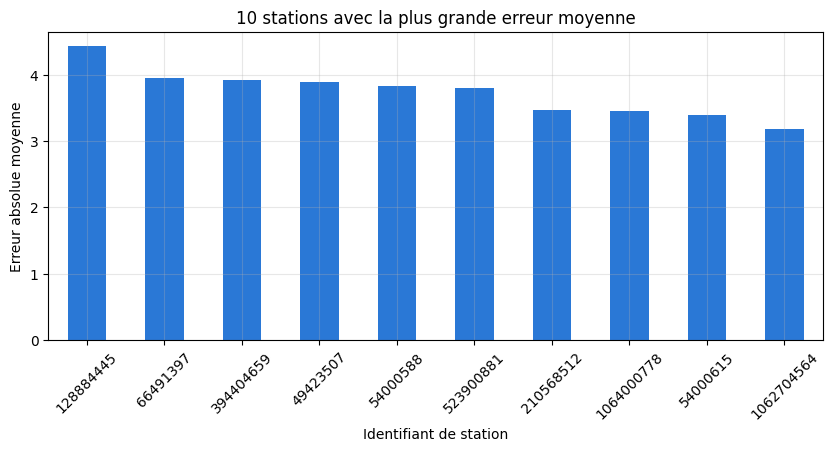

In [ ]:
plt.figure(figsize=(10, 4))
erreurs_station.plot(kind="bar", color=BLEU)
plt.title("10 stations avec la plus grande erreur moyenne")
plt.xlabel("Identifiant de station")
plt.ylabel("Erreur absolue moyenne")
plt.xticks(rotation=45)
plt.show()

In [ ]:
alertes = resultats_stations[resultats_stations["velos_predits"] <= 2]

print("Nombre d'alertes 'presque vide' :", len(alertes))
print("Part des observations concernées :", round(len(alertes) / len(resultats_stations) * 100, 1), "%")

alertes[["station_id", "velos", "velos_futur", "velos_predits"]].head(10)

Nombre d'alertes 'presque vide' : 69664
Part des observations concernées : 9.8 %


,station_id,velos,velos_futur,velos_predits
2216125,128834707,3,2,1.933000
2216143,78374110,1,2,0.970000
2216147,35380305,0,0,0.029167
2216159,48800374,2,2,1.362667
2216161,569583918,2,2,1.770333
2216166,1063971944,1,1,1.000000
2216172,27415411,1,1,1.050000
2216183,66489651,1,1,1.000000
2216185,49498164,2,2,1.924000
2216193,82379648,0,0,0.000000


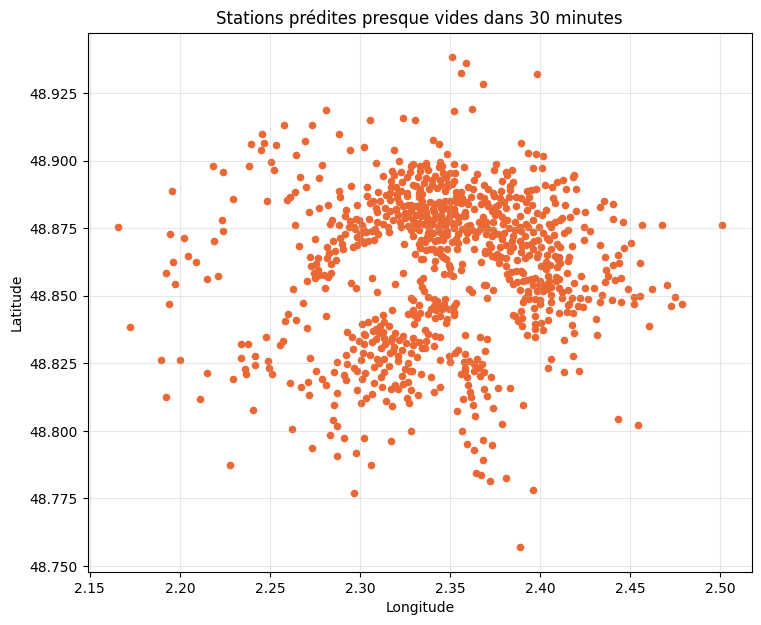

,name,velos,velos_futur,velos_predits
0,Jean-Jacques Rousseau - Deux Ecus,3,2,1.933000
1,Square Pierre Lazareff,1,2,0.970000
2,Le Goff - Gay-Lussac,0,0,0.029167
3,Place de l'Hôtel de Ville,2,2,1.362667
4,Choiseul - Quatre Septembre,2,2,1.770333
5,Saint-Michel - Luxembourg,1,1,1.000000
6,Frères Flavien - Porte des Lilas,1,1,1.050000
7,Louis le Grand - Italiens,1,1,1.000000
8,Mairie du 8ème,2,2,1.924000
9,Lisbonne - Monceau,0,0,0.000000


In [ ]:
carte_alertes = (
    alertes
    .drop_duplicates("station_id")
    .merge(ref[["station_id", "name", "lat", "lon"]], on="station_id", how="left")
)

plt.figure(figsize=(9, 7))
plt.scatter(carte_alertes["lon"], carte_alertes["lat"], s=20, color=ORANGE)
plt.title("Stations prédites presque vides dans 30 minutes")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.gca().set_aspect(1.5)
plt.show()

carte_alertes[["name", "velos", "velos_futur", "velos_predits"]].head(10)